# From source preparation to observer recovery

How does a prepared diary state become information available to a finite observer? This notebook generates 32 Hayden–Preskill source states, solves scalar-wave scattering in Schwarzschild spacetime, propagates five packets, and integrates their interaction with the detector. The resulting carrier probabilities determine the recovery bounds.

Run the cells in order. Source states, scattering, waveforms, and detector probabilities are generated before the supplied reference arrays are loaded for comparison. Generated arrays, tables, and the access figure are saved in `outputs/runs/<run>/upstream/`. The numerical conventions below specify the calculation from the random draws through the detector integration.

In [1]:
from pathlib import Path
import os, datetime
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from scipy.optimize import brentq
sys.path.insert(0,str(Path('code').resolve()))
from source_tables import generate_source_tables
from propagation import scalar_transmission, TransmissionGrid, generate_envelopes
from causal_filter import channel_for_packets, FilterParameters
from cavity import mask_weights, qec_value, root_bisection
OUT=Path('outputs/runs') / os.environ.get('ODER_RUN_NAME', datetime.datetime.now().strftime('%Y%m%d_%H%M%S')) / 'upstream'; OUT.mkdir(parents=True,exist_ok=True)
registry=json.loads(Path('inputs/observer_registry.json').read_text())
start=time.perf_counter()
with threadpool_limits(limits=1):
    joint,sx,sqx,source_diagnostics=generate_source_tables(
        registry['hp']['first_seed'],registry['hp']['ensemble_size'])
assert joint.shape==(32,32,32)
assert max(d['unitary_residual'] for d in source_diagnostics)<2e-12
assert max(d['normalization_error'] for d in source_diagnostics)<2e-12
np.save(OUT/'generated_source_information.npy',joint)
np.savez_compressed(OUT/'generated_source_entropies.npz',sx=sx,sqx=sqx)
print('Generated all 32 source states and subset information in',round(time.perf_counter()-start,2),'seconds')


Generated all 32 source states and subset information in 10.35 seconds


## Propagate the packets and collect their energy

With $M=1$, the radial potential is

$$V_\ell(r)=(1-2/r)\left[\frac{\ell(\ell+1)}{r^2}+\frac{2}{r^3}\right].$$

A purely ingoing near-horizon solution is matched to incoming and outgoing waves at the outer boundary. The complex transmission amplitude is $1/A_{\rm in}$. Conservation of transmitted and reflected flux provides a check on the radial solution.

The packet integral and arrival calibration then give the five propagated waveforms. Starting with an empty cavity, the detector equation tracks detected energy, energy still stored in the cavity, and energy returned through the inaccessible reflected port. The next cell repeats this calculation for the baseline and two refinement settings.


In [2]:
dt=registry['time']['dt_refined_M']
times=np.arange(0,registry['time']['terminal_M']+dt/2,dt)
eta=registry['observer']['aperture_fraction']*registry['observer']['efficiency']
filter_parameters=FilterParameters(registry['filter']['center_local_Momega'],
    registry['filter']['kappa_total_per_M'],
    registry['filter']['kappa_in_fraction'],registry['filter']['kappa_detector_fraction'])
assert len(set(registry['packet']['centers_Momega']))==1, 'This notebook uses equal carrier center frequencies.'
runs={}; rows=[]
settings=[('baseline',321,{}),('grid_refined',641,{}),
          ('physical_refined',641,dict(eps=3e-7,rmax_factor=65.,rtol=3e-11,atol=3e-13))]
for name,n,options in settings:
    start=time.perf_counter()
    frequencies=np.linspace(.004,.384,n)
    solved=np.array([scalar_transmission(float(w),**options) for w in frequencies])
    transmission=TransmissionGrid(frequencies,solved[:,0])
    envelopes,delay=generate_envelopes(times,transmission,
        spectral_points=registry['packet']['spectral_points_refined'],
        center_momega=registry['packet']['centers_Momega'][0],
        fractional_width=registry['packet']['fractional_width'],
        arrivals=registry['packet']['arrival_centers_observer_input_M'],
        radius_r_over_2M=registry['observer']['radius_r_over_2M'])
    global_carriers,observer_carriers,diags,cavities=channel_for_packets(
        times,envelopes,eta=eta,filter_parameters=filter_parameters)
    flux=float(np.max(abs(solved[:,1])))
    balance=max(d['maximum_energy_balance_residual'] for d in diags)
    assert flux<2e-8 and balance<registry['gates']['energy_balance_residual']
    assert np.max(observer_carriers-global_carriers)<registry['gates']['carrier_nesting_violation']
    runs[name]=dict(times=times,envelopes=envelopes,global_carriers=global_carriers,
        observer_carriers=observer_carriers,cavities=cavities)
    np.savez_compressed(OUT/(name+'.npz'),**runs[name])
    rows.append(dict(run=name,nodes=n,flux_residual=flux,balance_residual=balance,
                     source_delay_M=delay,seconds=time.perf_counter()-start))
    print(name,'completed')
display(pd.DataFrame(rows))


baseline completed


grid_refined completed


physical_refined completed


,run,nodes,flux_residual,balance_residual,source_delay_M,seconds
0,baseline,321,1.358402e-09,2.622035e-15,5.041784,16.783110
1,grid_refined,641,1.358402e-09,2.798976e-15,5.041784,23.128032
2,physical_refined,641,4.327072e-11,2.850151e-15,5.041607,37.872161


## Compare with reference outputs and check refinement

The reference arrays are first loaded in the next cell. Source-information comparisons cover every seed and subset; the first-seed entropy comparisons also test the quantities from which that information is calculated. Waveform and carrier comparisons show the differences between the generated scattering calculation and the reference outputs.

The refinement table measures the effect of a denser frequency grid and more demanding radial integration settings. These are numerical convergence checks. The uniform analytic bounds for the finite receiver are evaluated separately in `Finite_Receiver.ipynb`.

The final table compares input and detector-output peak times. It checks the mean detector response delay against the manuscript's $3.7954M$.


In [3]:
archive=np.load('inputs/closure_reproduction_inputs.npz')
old_joint=np.load('inputs/hp_joint_information.npy')
old_entropy=np.load('inputs/hp_first_seed_entropies.npz')
source_error=float(np.max(abs(joint-old_joint)))
entropy_error=float(max(np.max(abs(sx-old_entropy['sx'])),np.max(abs(sqx-old_entropy['sqx']))))
assert source_error<2e-12 and entropy_error<2e-12
comparisons=[]
for name,run in runs.items():
    for quantity in ('envelopes','global_carriers','observer_carriers'):
        comparisons.append(dict(run=name,quantity=quantity,
            maximum_absolute_difference=float(np.max(abs(run[quantity]-archive[quantity])))))
comparison=pd.DataFrame(comparisons);display(comparison)
refinements=[]
for left,right in [('baseline','grid_refined'),('grid_refined','physical_refined')]:
    for quantity in ('envelopes','global_carriers','observer_carriers'):
        refinements.append(dict(comparison=left+' to '+right,quantity=quantity,
            maximum_absolute_change=float(np.max(abs(runs[left][quantity]-runs[right][quantity])))))
display(pd.DataFrame(refinements))
for run in runs.values():
    assert np.max(abs(run['observer_carriers'][-1]-archive['observer_carriers'][-1]))<registry['gates']['terminal_refinement_difference']
print('Maximum source-information difference:',source_error)
print('Maximum first-seed entropy difference:',entropy_error)
comparison.to_csv(OUT/'archive_comparison.csv',index=False)
pd.DataFrame(refinements).to_csv(OUT/'refinement.csv',index=False)

for left,right in [('baseline','grid_refined'),('grid_refined','physical_refined')]:
    for quantity in ('global_carriers','observer_carriers'):
        assert np.max(abs(runs[left][quantity][-1]-runs[right][quantity][-1]))<registry['gates']['terminal_refinement_difference']


# Detector response delay: compare peaks of input current and detector output.
from propagation import peak_location
response_rows=[]
for name,run in runs.items():
    delays=[peak_location(times,abs(run['cavities'][:,i])**2)
            -peak_location(times,abs(run['envelopes'][:,i])**2) for i in range(5)]
    mean_delay=float(np.mean(delays))
    response_rows.append(dict(run=name,mean_response_delay_M=mean_delay,
        difference_from_archived_primary_M=mean_delay-3.795408860842256))
    # The manuscript reports 3.7954 M, to four decimal places.
    assert abs(mean_delay-3.7954)<0.00005
display(pd.DataFrame(response_rows))
pd.DataFrame(response_rows).to_csv(OUT/'response_delay.csv',index=False)


,run,quantity,maximum_absolute_difference
0,baseline,envelopes,8.697447e-09
1,baseline,global_carriers,6.797484e-09
2,baseline,observer_carriers,4.361954e-09
3,grid_refined,envelopes,9.085742e-09
4,grid_refined,global_carriers,1.076155e-08
5,grid_refined,observer_carriers,6.882925e-09
6,physical_refined,envelopes,3.825973e-07
7,physical_refined,global_carriers,2.184306e-08
8,physical_refined,observer_carriers,1.315821e-08


,comparison,quantity,maximum_absolute_change
0,baseline to grid_refined,envelopes,1.261149e-09
1,baseline to grid_refined,global_carriers,4.897263e-09
2,baseline to grid_refined,observer_carriers,3.125876e-09
3,grid_refined to physical_refined,envelopes,3.735127e-07
4,grid_refined to physical_refined,global_carriers,1.315351e-08
5,grid_refined to physical_refined,observer_carriers,7.673306e-09


Maximum source-information difference: 3.1086244689504383e-15
Maximum first-seed entropy difference: 3.552713678800501e-15


,run,mean_response_delay_M,difference_from_archived_primary_M
0,baseline,3.795409,-5.417516e-09
1,grid_refined,3.795409,-4.775607e-09
2,physical_refined,3.795409,-9.657415e-08


## Calculate the recovery bounds for each source state

Each seed is evaluated separately. Inverting the binary relative-entropy bound gives a fidelity ceiling; the conditional-entropy recovery bound gives a fidelity floor. The table brings these bounds together with global information, observer information, and the early-access threshold.

The checks compare the freshly generated calculation with the reference results using the stated tolerances. They also test the manuscript's conservative fidelity bounds. The displayed differences show the precision at which the two numerical implementations agree.


In [4]:
def scores(source,run):
    p=run['observer_carriers'][-1];wg=mask_weights(run['global_carriers'][-1])
    early=np.einsum('s,nst->nt',mask_weights(p),source)
    def div(f):
        return 2. if f==1 else f*np.log2(f/.25)+(1-f)*np.log2((1-f)/.75)
    upper=np.array([brentq(lambda f:div(f)-2*e,.25,1.) for e in early[:,0]])
    lower=2**(2*early[:,31]-2)
    global_e=np.einsum('s,ns->n',wg,source[:,:,31])
    alpha=np.array([root_bisection(s,p) for s in source])
    return dict(global_e=global_e,early=early,upper=upper,lower=lower,alpha=alpha,
                qec=qec_value(p))
reference=scores(old_joint,archive); summaries=[]
for name,run in runs.items():
    s=scores(joint,run)
    assert np.all(s['early'][:,0]<.5) and np.all(s['early'][:,31]>.5)
    assert np.max(s['early'][:,31]-s['global_e'])<2e-10
    assert s['upper'].max()<.3572 and s['lower'].min()>.8155
    assert np.max(abs(s['early']-reference['early']))<registry['gates']['independent_supply_difference']
    assert abs(s['qec']-reference['qec'])<registry['gates']['independent_supply_difference']
    summaries.append(dict(run=name,mean_global=s['global_e'].mean(),
        mean_no_early=s['early'][:,0].mean(),mean_full_early=s['early'][:,31].mean(),
        fidelity_ceiling=s['upper'].max(),fidelity_floor=s['lower'].min(),
        first_alpha=s['alpha'][0],qec_supply=s['qec'],
        maximum_statewise_information_difference=float(np.max(abs(s['early']-reference['early'])))))
    pd.DataFrame(dict(seed=2026082100+np.arange(32),global_e=s['global_e'],
        no_early=s['early'][:,0],full_early=s['early'][:,31],alpha=s['alpha'],
        ceiling=s['upper'],floor=s['lower'])).to_csv(OUT/(name+'_statewise.csv'),index=False)
display(pd.DataFrame(summaries))
pd.DataFrame(summaries).to_csv(OUT/'regenerated_recovery.csv',index=False)


from recovery_certificates import statewise as recovery_certificates
branch_rows=[]
for name,run in runs.items():
    certificate=pd.DataFrame(recovery_certificates(joint,run['observer_carriers'][-1]))
    certificate.to_csv(OUT/(name+'_branch_certificates.csv'),index=False)
    hi=certificate.no_early_branch_upper.max();lo=certificate.full_early_branch_lower.min()
    assert hi < .3308 and lo > .8476
    branch_rows.append(dict(run=name,branch_ceiling=hi,branch_floor=lo))
display(pd.DataFrame(branch_rows))


,run,mean_global,mean_no_early,mean_full_early,fidelity_ceiling,fidelity_floor,first_alpha,qec_supply,maximum_statewise_information_difference
0,baseline,0.976589,0.018876,0.856854,0.357162,0.815598,0.661428,0.397931,3.834045e-09
1,grid_refined,0.976589,0.018876,0.856854,0.357162,0.815598,0.661428,0.397931,8.128663e-09
2,physical_refined,0.976589,0.018876,0.856854,0.357162,0.815598,0.661428,0.397931,7.908633e-09


,run,branch_ceiling,branch_floor
0,baseline,0.330718,0.847608
1,grid_refined,0.330718,0.847608
2,physical_refined,0.330718,0.847608


## See how joint access changes recovery

The following curves use the generated source tables and detector probabilities. They compare independent possession of early-radiation carriers with receiving all of those carriers together. Both laws have the same marginal possession probability for each carrier, so their difference isolates the effect of joint access.

The final checks compare two fixed access laws across all 32 source states and the five-share code. Their reversed ordering shows why the source encoding matters when evaluating an access law.


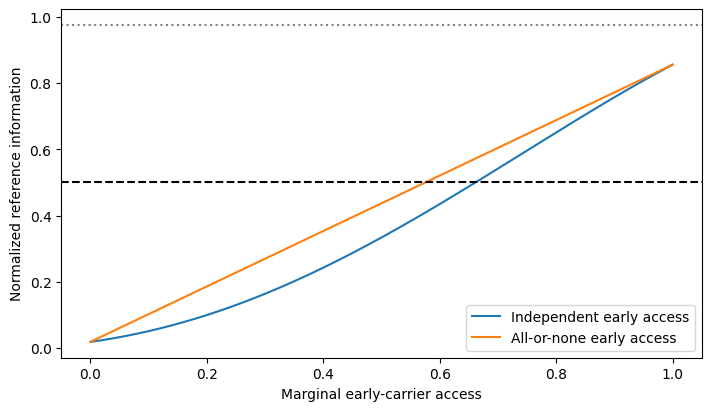

All 32 source states retain the access separation and source-dependent ordering reversal.


In [5]:
run=runs['baseline'];s=scores(joint,run)
a=np.linspace(0,1,201);W=np.array([mask_weights(np.full(5,x)) for x in a])
f=s['early'][0]
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
ax.plot(a,W@f,label='Independent early access')
ax.plot(a,(1-a)*f[0]+a*f[31],label='All-or-none early access')
ax.axhline(.5,color='black',linestyle='--');ax.axhline(s['global_e'][0],color='gray',linestyle=':')
ax.set(xlabel='Marginal early-carrier access',ylabel='Normalized reference information');ax.legend()
fig.savefig(OUT/'regenerated_access.pdf');plt.show()
counts=np.array([m.bit_count() for m in range(32)])
three=np.where(counts==3,.1,0.);all_or_none=np.zeros(32);all_or_none[[0,31]]=[.4,.6]
assert np.all(s['early']@three<.5) and np.all(s['early']@all_or_none>.5)
qec_indicator=(counts>=3).astype(float)
assert qec_indicator@three>qec_indicator@all_or_none
print('All 32 source states retain the access separation and source-dependent ordering reversal.')


## Numerical conventions

The random-number, QR-phase, and register-ordering conventions were selected using four first-seed entropy pairs. The remaining 31 seeds and additional subset values provide further checks. No continuous scale was fitted to a target result.

The source uses NumPy's `default_rng` (PCG64) with seeds 2026082100 through 2026082131. Each 64×64 complex Gaussian matrix draws all real entries before all imaginary entries. QR factorization multiplies column $j$ of $Q$ by $R_{jj}/|R_{jj}|$. The resulting Haar unitary acts on the diary and five black-hole qubits. Its C-order output/input reshape is $(C,D,A,B)$, transposed to $(Q,C,D,E)$ and divided by $\sqrt{64}$. Each register is then represented by individual qubit axes. Subsystem entropies use base-two logarithms and retain eigenvalues greater than $10^{-15}$.

With $x=M\omega$ and $M=1$, the radial equation is $d^2\psi/dr_*^2+(x^2-V_\ell)\psi=0$, where $r_*=r+2\log(r/2-1)$. The scalar channel uses $\ell=0$. At $r_0=2(1+\varepsilon)$, impose $\psi=e^{-ixr_*}$ and $d\psi/dr_*=-ix\psi$. At the outer boundary, match incoming and outgoing plane waves and set the transmission amplitude to $1/A_{\rm in}$.

| Setting | Baseline | Frequency refinement | Boundary and solver refinement |
| --- | --- | --- | --- |
| Uniform frequency nodes on $[0.004,0.384]$ | 321 | 641 | 641 |
| $\varepsilon$ | $10^{-6}$ | $10^{-6}$ | $3\times10^{-7}$ |
| Outer radius | $\max(120,40/\max(x,0.01))$ | Same | $\max(120,65/\max(x,0.01))$ |
| DOP853 relative tolerance | $2\times10^{-9}$ | Same | $3\times10^{-11}$ |
| DOP853 absolute tolerance | $2\times10^{-11}$ | Same | $3\times10^{-13}$ |

A piecewise cubic Hermite interpolator (PCHIP) interpolates the real and imaginary transmission amplitudes separately. Packet normalization is a separate physical convention from the first-seed entropy calibration. The incident Gaussian spectral density is

$$q(x)=\frac{\exp[-(x-x_0)^2/(2\sigma^2)]}{\sigma\sqrt{2\pi}\,\Phi(x_0/\sigma)},\qquad x\geq0,$$

where $\Phi$ is the standard normal cumulative distribution. Thus $\int_0^\infty q(x)\,dx=1$. This fixes the incident packet's unit normalization analytically, independently of the finite time window and the entropy comparisons. The finite frequency grid approximates that integral; the packet is not renormalized on the grid or within the collection window. Its center is $x_0=0.16$ and standard deviation is $0.032$. Packet quadrature uses 2,401 nodes between $\max(0.004,x_0-7\sigma)$ and $x_0+7\sigma$. A zero-centered packet is evaluated on 3,601 times in $[-16,20]$ to determine the arrival shift by parabolic peak interpolation. The five registered input peaks are $(28,40,52,64,76)M$.

The observer sits at $r=20M$, with lapse $\sqrt{0.9}$, aperture 0.72, efficiency 0.88, and collection deadline $120M$. The time step is $0.05M$. The cavity starts empty, has equal input and detector ports, linewidth $M\kappa=0.515$, and local center frequency $0.16/\sqrt{0.9}$.

The reference comparisons test all source/subset information values, first-seed entropies, waveforms, terminal carrier probabilities, and recovery bounds. Flux and energy-balance residuals must remain below $2\times10^{-8}$. Carrier nesting and source data-processing checks allow $2\times10^{-9}$; subset monotonicity and block-density checks allow $2\times10^{-10}$. Terminal refinement and independent carrier comparisons allow $8\times10^{-4}$, while independent information-supply comparisons allow $1.5\times10^{-3}$. The executable cells retain their additional, more precise comparison checks.

## What the calculation establishes

Source preparation, scattering, propagation, and causal collection jointly determine the observer's recovery bounds. The reference comparisons quantify numerical agreement, while the refinements test stability under changes in resolution and radial integration. The access separation and source-dependent ordering reversal persist through these checks.

Equal individual access probabilities do not specify which diary correlations arrive together. The collection law must be evaluated against the source state, and the comparison tables show the numerical precision at which those conclusions are supported.